# Analysis: EDA and statistical tests

**ZHAW Data Analytics HS2026 · Group project «Electricity prices of Swiss municipalities» · Part Subraj**

This notebook covers mandatory requirement 4 (EDA, graphical and non-graphical) and bonus point 4 (ANOVA and correlation with p-values). Regression, model quality and k-means follow in a second part (`04_modell_subraj.ipynb`).

**Research question:** Which characteristics of a municipality explain the level of its household electricity price, and did these relationships change with the price increase of 2023?

**Data basis:** Category H4 (4500 kWh per year), product `standard`, the 2,087 municipalities that have a price in all three years. The time comparison uses only `total`, because only this column contains the same components in all three years (project guide, section 4).

| Section | Content | Sub-question |
|---|---|---|
| 0 | Load data from SQLite | |
| 1 | Overview and data quality | |
| 2 | Distribution of prices per year | 1 |
| 3 | Change between the years | 4 |
| 4 | Price components | 1 |
| 5 | Municipal characteristics | 2 |
| 6 | Language regions and cantons | 1 |
| 7 | Grid operators | caveat 5b |
| 8 | Tests: t-test, ANOVA, correlation | 1, 2, 4 |
| 9 | Interim conclusion | |

## 0 · Load data

The analysis table comes from Metehan's SQLite database (`v_analyse`, one row per municipality), the price components from `v_preis_h4`. Both queries run as SQL from Python.

Canton, language region and municipality type are not yet in the database, only in Lenny's joined table. They are added via `gemeinde_nr`, as is the assignment of the grid operator (for municipalities with several operators, the one with the smallest `netzbetreiber_id`).

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


def finde_wurzel(start: Path) -> Path:
    # Climbs upwards until daten/ and scripts/ sit side by side
    for ordner in [start, *start.parents]:
        if (ordner / "daten").is_dir() and (ordner / "scripts").is_dir():
            return ordner
    raise RuntimeError(f"Repository root not found starting from {start}")


WURZEL = finde_wurzel(Path.cwd().resolve())
DB = WURZEL / "sql" / "strompreise.db"
VERBUNDEN = WURZEL / "daten" / "verbunden" / "strompreise_gemeinden.csv"
JAHRE = [2021, 2024, 2027]

# Colours: fixed order, checked for colour vision deficiency
FARBE = {2021: "#2a78d6", 2024: "#eb6834", 2027: "#1baf7a"}
REGION_FARBE = {"Deutsch": "#2a78d6", "Französisch": "#eb6834",
                "Italienisch": "#1baf7a", "Rätoromanisch": "#eda100"}
# The values of sprachregion are German words in the data; translated for display only (glossar.md, 0b)
ANZEIGE_SPRACHE = {"Deutsch": "German", "Französisch": "French",
                   "Italienisch": "Italian", "Rätoromanisch": "Romansh"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781",
    "ytick.color": "#898781", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
con = sqlite3.connect(DB)

df = pd.read_sql("SELECT * FROM v_analyse", con)
bestandteile = pd.read_sql("""
    SELECT p.*
    FROM v_preis_h4 p
    JOIN v_analyse a ON a.gemeinde_nr = p.gemeinde_nr      -- only the 2087 municipalities of the analysis
""", con)

zusatz = pd.read_csv(VERBUNDEN, usecols=["gemeinde_nr", "netzbetreiber_id", "netzbetreiber",
                                         "kanton", "kanton_nr", "sprachregion", "gemeindetyp_9",
                                         "anz_gemeinden_betreiber"])
vorher = len(df)
df = df.merge(zusatz, on="gemeinde_nr", how="left", validate="one_to_one")
assert len(df) == vorher == 2087, "Number of rows changed during the join"
assert df["kanton"].notna().all(), "Municipality without canton"

# Changes in centimes per kWh
df["anstieg_21_24"] = df["total_2024"] - df["total_2021"]
df["anstieg_24_27"] = df["total_2027"] - df["total_2024"]
df["anstieg_21_27"] = df["total_2027"] - df["total_2021"]

print(f"{len(df)} municipalities, {df['netzbetreiber_id'].nunique()} grid operators, "
      f"{df['kanton'].nunique()} cantons")
print(f"Components: {len(bestandteile)} rows ({bestandteile['jahr'].value_counts().sort_index().to_dict()})")

2087 municipalities, 485 grid operators, 26 cantons
Components: 6261 rows ({2021: 2087, 2024: 2087, 2027: 2087})


## 1 · Overview and data quality

In [3]:
df.head()

,gemeinde_nr,gemeinde,anzahl_netzbetreiber,total_2021,total_2024,total_2027,einwohner,dichte,flaeche_total,beschaeftigte,anteil_65plus,netzbetreiber_id,netzbetreiber,kanton,kanton_nr,sprachregion,gemeindetyp_9,anz_gemeinden_betreiber,anstieg_21_24,anstieg_24_27,anstieg_21_27
0,1,Aeugst am Albis,1,17.122,31.609,23.872,1981.0,250.442478,7.91,442.0,18.021201,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,23.0,133,14.487,-7.737,6.75
1,2,Affoltern am Albis,1,17.122,31.609,23.872,12303.0,1161.756374,10.59,6920.0,18.166301,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,11.0,133,14.487,-7.737,6.75
2,3,Bonstetten,1,17.122,31.609,23.872,5572.0,749.932705,7.43,1014.0,16.529074,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,22.0,133,14.487,-7.737,6.75
3,4,Hausen am Albis,1,17.122,31.609,23.872,3751.0,275.808824,13.60,1021.0,17.995201,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,22.0,133,14.487,-7.737,6.75
4,5,Hedingen,1,17.122,31.609,23.872,3778.0,578.560490,6.53,1478.0,16.728428,486,Elektrizitätswerke des Kantons Zürich (EKZ),ZH,1,Deutsch,11.0,133,14.487,-7.737,6.75


In [4]:
uebersicht = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "distinct_values": df.nunique(),
})
uebersicht

,dtype,missing,missing_%,distinct_values
gemeinde_nr,int64,0,0.0,2087
gemeinde,str,0,0.0,2087
anzahl_netzbetreiber,int64,0,0.0,4
total_2021,float64,0,0.0,663
total_2024,float64,0,0.0,663
total_2027,float64,0,0.0,672
einwohner,float64,0,0.0,1726
dichte,float64,0,0.0,2082
flaeche_total,float64,0,0.0,1447
beschaeftigte,float64,88,4.2,1338


Missing values occur in only two places. `beschaeftigte` (jobs) lacks 88 values because the Federal Statistical Office (FSO) suppresses them for reasons of statistical confidentiality (status Q). These municipalities are clearly smaller than the rest (integration documentation, section 7). `gemeindetyp_9` lacks one value (Prez, a merger of predecessors with different types). For the model this means: one variant without jobs on all 2,087 municipalities, one variant with jobs on 1,999 municipalities, and a comparison of both.

In [5]:
# Plausibility: no negative or zero values in variables that will be log-transformed later
for spalte in ["einwohner", "dichte", "flaeche_total", "beschaeftigte"]:
    print(f"{spalte:<15} smallest value: {df[spalte].min():>10.2f}   values <= 0: {(df[spalte] <= 0).sum()}")
print("\nMunicipalities with several grid operators:", (df["anzahl_netzbetreiber"] > 1).sum())
print("Duplicate gemeinde_nr:", df["gemeinde_nr"].duplicated().sum())

einwohner       smallest value:      32.00   values <= 0: 0
dichte          smallest value:       0.86   values <= 0: 0
flaeche_total   smallest value:       0.31   values <= 0: 0
beschaeftigte   smallest value:      11.00   values <= 0: 0

Municipalities with several grid operators: 150
Duplicate gemeinde_nr: 0


## 2 · Distribution of prices per year

### 2.1 Key figures
Besides mean and median, measures of dispersion are computed. The coefficient of variation (standard deviation divided by mean) makes the dispersion comparable between years with different price levels.

In [6]:
def kennzahlen(x: pd.Series) -> pd.Series:
    q1, q3 = x.quantile([0.25, 0.75])
    return pd.Series({
        "n": x.count(), "Mean": x.mean(), "Median": x.median(), "Std": x.std(),
        "Min": x.min(), "Q1": q1, "Q3": q3, "Max": x.max(), "IQR": q3 - q1,
        "Range": x.max() - x.min(), "Coeff. of var.": x.std() / x.mean(),
        "Skewness": x.skew(), "Kurtosis": x.kurt(),
        "Outliers (1.5 IQR)": ((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum(),
    })

preis_kennzahlen = pd.DataFrame({j: kennzahlen(df[f"total_{j}"]) for j in JAHRE}).round(2)
preis_kennzahlen

,2021,2024,2027
n,2087.00,2087.00,2087.00
Mean,20.86,31.99,27.25
Median,20.53,32.15,26.91
Std,2.99,3.71,3.05
Min,7.96,10.22,10.56
Q1,19.09,30.27,25.59
Q3,22.51,33.36,28.79
Max,27.65,50.62,45.88
IQR,3.42,3.09,3.20
Range,19.69,40.39,35.32


### 2.2 Histograms

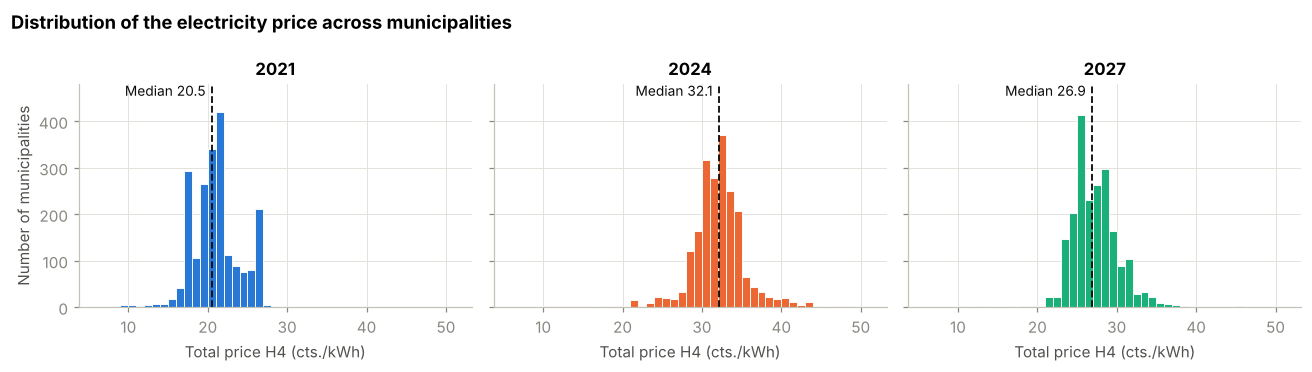

In [7]:
fig, achsen = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True, sharey=True)
bins = np.arange(6, 52, 1)
for ax, j in zip(achsen, JAHRE):
    x = df[f"total_{j}"]
    ax.hist(x, bins=bins, color=FARBE[j], edgecolor="white", linewidth=0.6)
    ax.axvline(x.median(), color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.text(x.median() - 0.8, 455, f"Median {x.median():.1f}", fontsize=9,
            color="#0b0b0b", ha="right")
    ax.set_title(str(j))
    ax.set_xlabel("Total price H4 (cts./kWh)")
achsen[0].set_ylabel("Number of municipalities")
achsen[0].set_ylim(0, 480)
fig.suptitle("Distribution of the electricity price across municipalities", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

### 2.3 Box plots

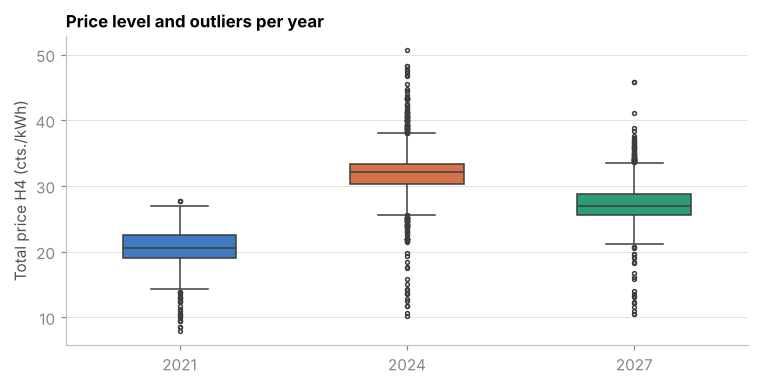

In [8]:
lang = df.melt(id_vars="gemeinde_nr", value_vars=[f"total_{j}" for j in JAHRE],
               var_name="jahr", value_name="preis")
lang["jahr"] = lang["jahr"].str[-4:].astype(int)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.boxplot(data=lang, x="jahr", y="preis", hue="jahr", palette=FARBE, legend=False,
            width=0.5, fliersize=2.5, linewidth=1, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Total price H4 (cts./kWh)")
ax.set_title("Price level and outliers per year", loc="left")
fig.tight_layout()

#### Interpretation

In 2021, prices were tightly grouped around a median of 20.5 cts./kWh, and the distribution is not skewed. In 2024 the mean rose to 32.0 cts., an increase of 53 percent. At the same time the range doubled from 19.7 to 40.4 cts., and the number of outliers under the 1.5 IQR rule rose from 30 to 184. The kurtosis of 6.0 shows the same thing: most municipalities lie close together, but there are clearly more extreme values at both ends.

Relative to the price level, however, dispersion decreased. The coefficient of variation falls from 0.14 (2021) to 0.12 (2024) and 0.11 (2027). In centimes the differences between municipalities have grown, in relation to the price they have not.

In 2027 the median is 26.9 cts., 6.4 cts. above 2021. Prices have fallen, but not back to the pre-crisis level.

The 2021 histogram has conspicuous peaks, for example at 17 cts. These are not measurement errors: a large grid operator supplies hundreds of municipalities at the same price; EKZ, for instance, supplies all its municipalities at 17.1 cts. Section 7 deals with this.

## 3 · Change between the years

This matters for the second part of the research question: do cheap municipalities stay cheap, or does the crisis reshuffle the ranking? This is measured with Spearman's rank correlation between the years.

In [9]:
df[["anstieg_21_24", "anstieg_24_27", "anstieg_21_27"]].describe().round(2)

,anstieg_21_24,anstieg_24_27,anstieg_21_27
count,2087.00,2087.00,2087.00
mean,11.13,-4.74,6.39
std,4.39,3.10,3.86
min,1.20,-20.24,-2.15
25%,9.03,-5.93,4.77
50%,11.44,-4.68,6.75
75%,14.14,-3.89,8.41
max,31.37,11.32,27.65


In [10]:
print(f"Municipalities cheaper in 2027 than in 2021:       {(df['anstieg_21_27'] < 0).sum()} "
      f"({(df['anstieg_21_27'] < 0).mean():.1%})")
print(f"Municipalities more expensive in 2027 than in 2024: {(df['anstieg_24_27'] > 0).sum()} "
      f"({(df['anstieg_24_27'] > 0).mean():.1%})\n")

paare = [(2021, 2024), (2024, 2027), (2021, 2027)]
zeilen = []
for a, b in paare:
    sp = stats.spearmanr(df[f"total_{a}"], df[f"total_{b}"])
    pe = stats.pearsonr(df[f"total_{a}"], df[f"total_{b}"])
    zeilen.append({"Years": f"{a} – {b}",
                   "Spearman rho": round(sp.statistic, 3), "p (Spearman)": f"{sp.pvalue:.2g}",
                   "Pearson r": round(pe.statistic, 3), "p (Pearson)": f"{pe.pvalue:.2g}"})
rang = pd.DataFrame(zeilen)
rang

Municipalities cheaper in 2027 than in 2021:       227 (10.9%)
Municipalities more expensive in 2027 than in 2024: 165 (7.9%)



,Years,Spearman rho,p (Spearman),Pearson r,p (Pearson)
0,2021 – 2024,0.082,0.00017,0.155,1.1e-12
1,2024 – 2027,0.567,5.6e-178,0.594,3e-199
2,2021 – 2027,0.168,1e-14,0.184,2.4e-17


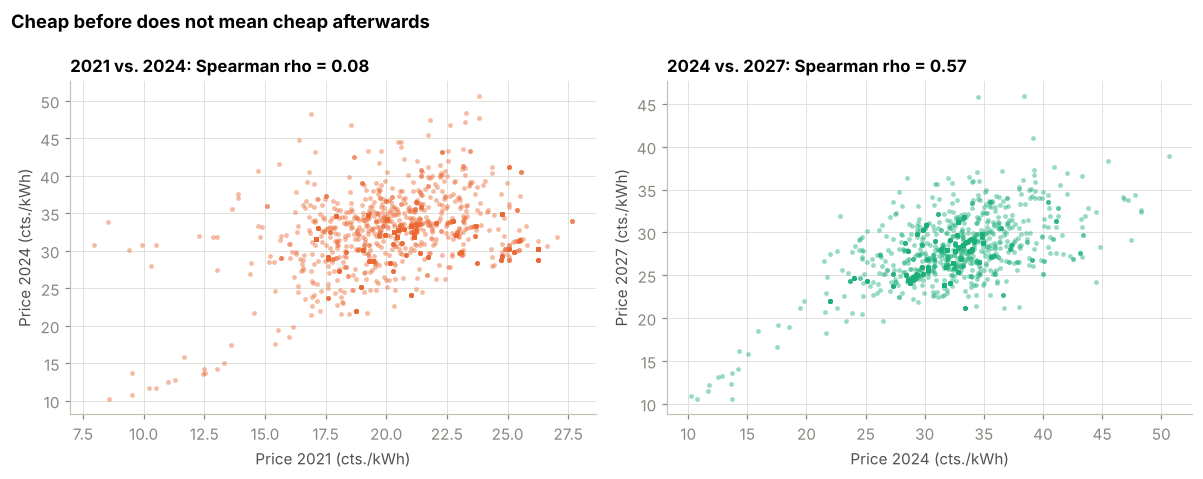

In [11]:
fig, achsen = plt.subplots(1, 2, figsize=(11, 4.4), sharex=False)
for ax, (a, b) in zip(achsen, [(2021, 2024), (2024, 2027)]):
    ax.scatter(df[f"total_{a}"], df[f"total_{b}"], s=10, alpha=0.45, color=FARBE[b], linewidths=0)
    rho = stats.spearmanr(df[f"total_{a}"], df[f"total_{b}"]).statistic
    ax.set_xlabel(f"Price {a} (cts./kWh)")
    ax.set_ylabel(f"Price {b} (cts./kWh)")
    ax.set_title(f"{a} vs. {b}: Spearman rho = {rho:.2f}", loc="left")
fig.suptitle("Cheap before does not mean cheap afterwards", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

#### Interpretation

The rank correlation between 2021 and 2024 is only 0.08. Where a municipality stood in the ranking before the crisis says almost nothing about where it stood at the peak. The crisis reshuffled the ranking. Between 2024 and 2027 the rank correlation is 0.57: municipalities that were expensive in 2024 tend to remain so in 2027.

In the left scatter plot, a small group in the lower left stands out, below 15 cts. in both years. An obvious guess is operators with their own generation, which were hardly affected by the market price. This has not been checked; the data contain no information on generation.

227 municipalities (10.9 percent) pay less in 2027 than in 2021, and 165 municipalities (7.9 percent) even pay more in 2027 than in 2024.

For the research question this means: if the ranking shifts this much, the municipal characteristics that explain the price in 2021 cannot be the same as in 2024. The model per year will show different coefficients.

## 4 · Price components

The price consists of four components: energy, grid usage (German: «Netznutzung»), levies to municipalities and cantons (German: «Abgaben») and the grid surcharge (German: «Netzzuschlag»). For averages across the years, grid usage is used **including** the metering tariff (German: «Messtarif») (`netznutzung_inkl_mess` from Metehan's view), because until 2025 the metering tariff was part of grid usage.

### 4.1 Average composition of the price

In [12]:
TEILE = ["energie", "netznutzung_inkl_mess", "abgaben", "netzzuschlag"]
NAMEN = {"energie": "Energy", "netznutzung_inkl_mess": "Grid usage incl. metering",
         "abgaben": "Levies", "netzzuschlag": "Grid surcharge"}
mittel = bestandteile.groupby("jahr")[TEILE + ["total"]].mean().round(2)
mittel

,energie,netznutzung_inkl_mess,abgaben,netzzuschlag,total
jahr,,,,,
2021,7.94,9.78,0.85,2.29,20.86
2024,15.58,13.23,0.88,2.30,31.99
2027,11.19,12.87,0.90,2.30,27.25


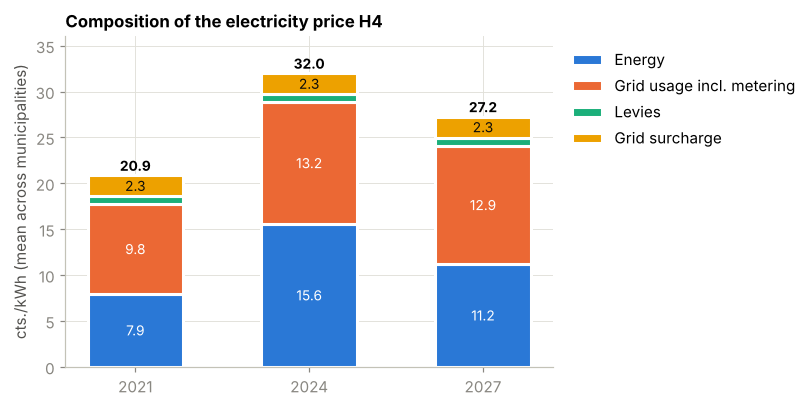

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
farben_teile = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
unten = np.zeros(len(JAHRE))
for teil, farbe in zip(TEILE, farben_teile):
    werte = mittel.loc[JAHRE, teil].values
    ax.bar([str(j) for j in JAHRE], werte, bottom=unten, color=farbe, width=0.55,
           edgecolor="white", linewidth=2, label=NAMEN[teil])
    for i, (w, u) in enumerate(zip(werte, unten)):
        if w > 1.5:
            ax.text(i, u + w / 2, f"{w:.1f}", ha="center", va="center", fontsize=9,
                    color="#0b0b0b" if farbe == "#eda100" else "white")
    unten += werte
for i, t in enumerate(mittel.loc[JAHRE, "total"]):
    ax.text(i, t + 0.5, f"{t:.1f}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("cts./kWh (mean across municipalities)")
ax.set_title("Composition of the electricity price H4", loc="left")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_ylim(0, 36)
fig.tight_layout()

### 4.2 Which component explains the differences between municipalities?

The mean says what the price consists of. The question here is a different one: which component makes one municipality more expensive than another? To answer it, the variance of the total price is decomposed. Because `total` is the sum of the components,

$\mathrm{Var}(\text{total}) = \sum_k \mathrm{Cov}(\text{component}_k, \text{total})$,

and the share of a component is $\mathrm{Cov}(\text{component}_k, \text{total}) / \mathrm{Var}(\text{total})$. The shares add up to 100 percent; individual shares can be negative.

In [14]:
def varianzanteile(gruppe: pd.DataFrame) -> pd.Series:
    var_total = gruppe["total"].var()
    return pd.Series({NAMEN[t]: gruppe[t].cov(gruppe["total"]) / var_total * 100 for t in TEILE})

anteile = bestandteile.groupby("jahr").apply(varianzanteile, include_groups=False).T.round(1)
anteile.loc["Sum"] = anteile.sum().round(1)
anteile

jahr,2021,2024,2027
Energy,32.0,80.3,44.8
Grid usage incl. metering,55.8,21.2,54.8
Levies,11.4,-1.4,0.4
Grid surcharge,0.8,-0.0,-0.0
Sum,100.0,100.1,100.0


#### Interpretation

On average the energy component almost doubled from 7.9 to 15.6 cts., grid usage rose from 9.8 to 13.2 cts. Levies and the grid surcharge stayed practically the same.

The variance decomposition shows that the cause of the differences between municipalities reversed. In 2021, grid usage explained 56 percent of the dispersion, that is the cost of the grid and thus geography. In 2024, energy explained 80 percent, that is how and when an operator bought its electricity. In 2027 the split is again similar to 2021 (energy 45, grid usage 55 percent).

The levies to municipalities still explained 11 percent of the differences in 2021, and practically nothing in 2024 and 2027.

The total for 2024 comes to 100.1 percent, which is a rounding effect.

## 5 · Municipal characteristics

The characteristics do not come from the same years as the prices: population, density and the share aged 65+ refer to 2019, jobs to 2018, area to 2016 (integration documentation, section 7b). Prices from 2021 to 2027 are therefore explained with municipal characteristics from 2016 to 2019. For area and density this is unproblematic, because they hardly change. For the share aged 65+ and population the gap to 2027 is larger, but the ranking of the municipalities has probably shifted only slightly. This has not been checked.

### 5.1 Distributions

In [15]:
MERKMALE = ["einwohner", "dichte", "flaeche_total", "beschaeftigte", "anteil_65plus"]
MERKMAL_NAME = {"einwohner": "Population", "dichte": "Density (pop./km²)",
                "flaeche_total": "Area (km²)", "beschaeftigte": "Jobs",
                "anteil_65plus": "Share aged 65+ (%)"}
merkmal_kennzahlen = pd.DataFrame({MERKMAL_NAME[m]: kennzahlen(df[m].dropna()) for m in MERKMALE}).T
merkmal_kennzahlen[["n", "Mean", "Median", "Std", "Min", "Max", "Skewness"]].round(1)

,n,Mean,Median,Std,Min,Max,Skewness
Population,2087.0,4071.1,1627.0,13118.8,32.0,420217.0,19.8
Density (pop./km²),2087.0,444.8,188.4,804.8,0.9,12811.0,5.9
Area (km²),2087.0,18.6,8.5,33.3,0.3,438.6,5.4
Jobs,1999.0,2572.7,623.0,14287.6,11.0,491193.0,23.9
Share aged 65+ (%),2087.0,19.4,19.0,4.4,6.5,40.3,0.8


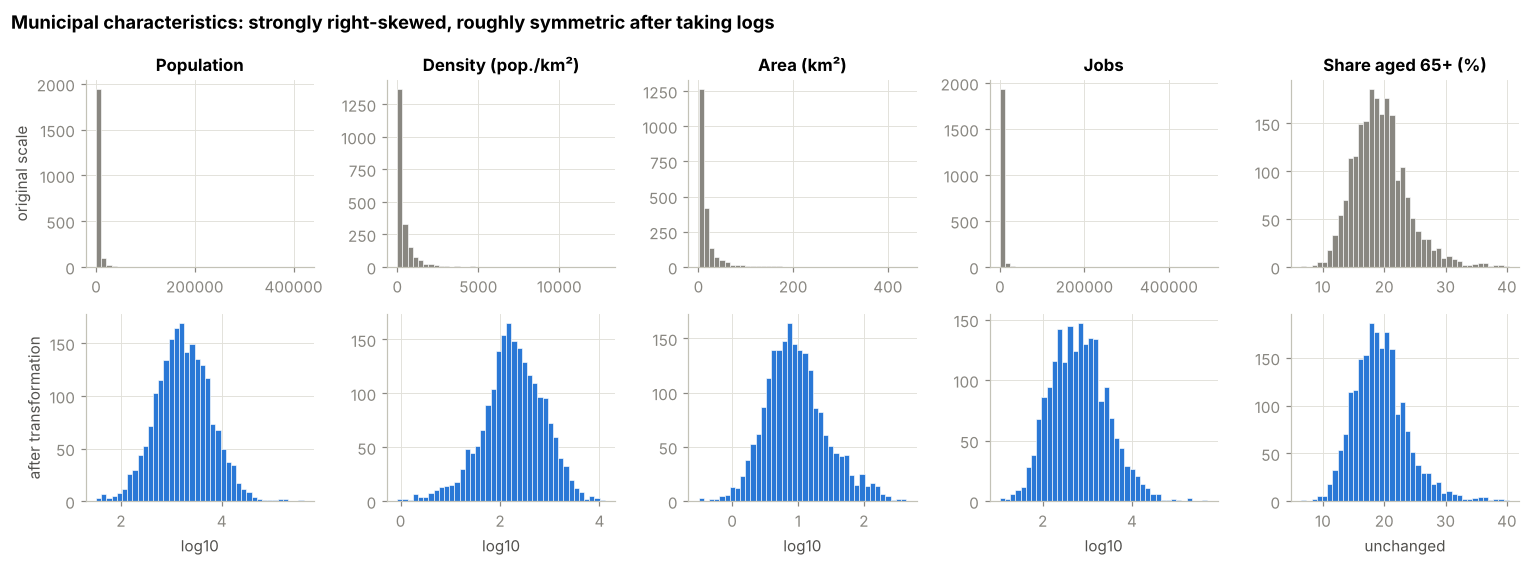

In [16]:
fig, achsen = plt.subplots(2, 5, figsize=(14, 5.2))
for i, m in enumerate(MERKMALE):
    x = df[m].dropna()
    achsen[0, i].hist(x, bins=40, color="#898781", edgecolor="white", linewidth=0.4)
    achsen[0, i].set_title(MERKMAL_NAME[m])
    if m == "anteil_65plus":
        achsen[1, i].hist(x, bins=40, color="#2a78d6", edgecolor="white", linewidth=0.4)
        achsen[1, i].set_xlabel("unchanged")
    else:
        achsen[1, i].hist(np.log10(x), bins=40, color="#2a78d6", edgecolor="white", linewidth=0.4)
        achsen[1, i].set_xlabel("log10")
achsen[0, 0].set_ylabel("original scale")
achsen[1, 0].set_ylabel("after transformation")
fig.suptitle("Municipal characteristics: strongly right-skewed, roughly symmetric after taking logs",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

Population, density, area and jobs are extremely right-skewed: mean population is about 4,100, the median about 1,600, because a few cities such as Zurich with over 400,000 inhabitants pull the mean up. After taking logs the distributions are roughly symmetric. For Pearson correlation and regression these four characteristics are therefore log-transformed. The share aged 65+ is already almost symmetric and stays unchanged.

In [17]:
# Log-transformed characteristics for correlation and model
for m in ["einwohner", "dichte", "flaeche_total", "beschaeftigte"]:
    df[f"log_{m}"] = np.log10(df[m])

# Relationship of the characteristics with each other (check multicollinearity in advance)
LOG_MERKMALE = ["log_einwohner", "log_dichte", "log_flaeche_total", "log_beschaeftigte", "anteil_65plus"]
df[LOG_MERKMALE].corr().round(2)

,log_einwohner,log_dichte,log_flaeche_total,log_beschaeftigte,anteil_65plus
log_einwohner,1.00,0.68,0.26,0.94,-0.14
log_dichte,0.68,1.00,-0.53,0.58,-0.30
log_flaeche_total,0.26,-0.53,1.00,0.31,0.24
log_beschaeftigte,0.94,0.58,0.31,1.00,-0.07
anteil_65plus,-0.14,-0.30,0.24,-0.07,1.00


Population and jobs are very strongly correlated, as are population and density. Using both in one regression would make the coefficients unstable. The model therefore has to choose, for example density and area instead of population, or jobs per inhabitant as a measure of commercial load.

### 5.2 Relationship with the price

Spearman rank correlation between each characteristic and the price or the increase. Spearman is insensitive to outliers and needs no transformation.

Below the heatmap, the p-value for each cell is shown. Because many tests run at the same time, the threshold is the Bonferroni correction (0.05 divided by the number of tests); an asterisk marks the values below it.

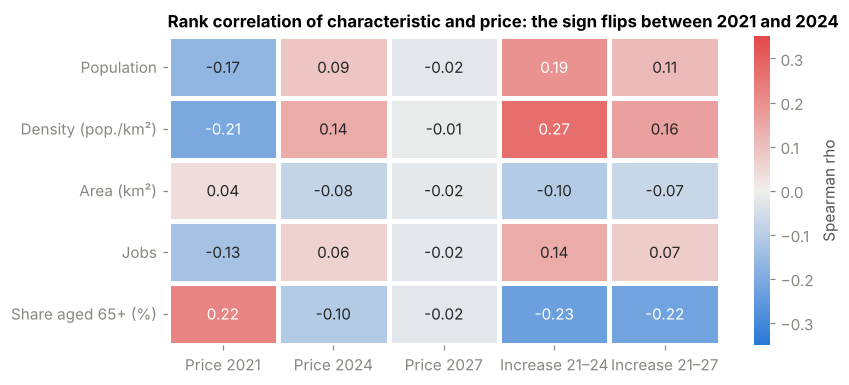

p-values (Spearman), 25 tests, Bonferroni threshold 0.05/25 = 0.0020
Significant after Bonferroni: 18 of 25



,Price 2021,Price 2024,Price 2027,Increase 21–24,Increase 21–27
Population,8.0e-15 *,9.8e-05 *,3.0e-01,2.6e-19 *,2.9e-07 *
Density (pop./km²),1.6e-21 *,6.5e-11 *,5.6e-01,2.4e-36 *,4.2e-14 *
Area (km²),8.7e-02,3.0e-04 *,3.7e-01,1.9e-06 *,1.2e-03 *
Jobs,3.0e-09 *,5.6e-03,3.2e-01,1.0e-10 *,1.1e-03 *
Share aged 65+ (%),3.0e-25 *,1.6e-06 *,2.7e-01,1.8e-27 *,1.2e-24 *


In [18]:
ZIELE = {"total_2021": "Price 2021", "total_2024": "Price 2024", "total_2027": "Price 2027",
         "anstieg_21_24": "Increase 21–24", "anstieg_21_27": "Increase 21–27"}
rho_matrix = pd.DataFrame(index=[MERKMAL_NAME[m] for m in MERKMALE], columns=list(ZIELE.values()), dtype=float)
p_matrix = rho_matrix.copy()
for m in MERKMALE:
    for ziel, name in ZIELE.items():
        paar = df[[m, ziel]].dropna()
        ergebnis = stats.spearmanr(paar[m], paar[ziel])
        rho_matrix.loc[MERKMAL_NAME[m], name] = ergebnis.statistic
        p_matrix.loc[MERKMAL_NAME[m], name] = ergebnis.pvalue

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(rho_matrix, annot=True, fmt=".2f", cmap=sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True),
            vmin=-0.35, vmax=0.35, linewidths=2, linecolor="white", cbar_kws={"label": "Spearman rho"}, ax=ax)
ax.set_title("Rank correlation of characteristic and price: the sign flips between 2021 and 2024", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout()
plt.show()

# p-value for each cell of the heatmap; Bonferroni threshold for all tests of this matrix
schwelle = 0.05 / p_matrix.size
print(f"p-values (Spearman), {p_matrix.size} tests, Bonferroni threshold 0.05/{p_matrix.size} = {schwelle:.4f}")
print(f"Significant after Bonferroni: {(p_matrix < schwelle).sum().sum()} of {p_matrix.size}\n")
p_matrix.map(lambda p: f"{p:.1e}" + (" *" if p < schwelle else ""))

#### Interpretation

The heatmap gives the most direct answer to the second part of the research question: the sign of the relationships flips.

In 2021, large and dense municipalities were cheaper (density rho = −0.21), and municipalities with a high share of people over 65 were more expensive (+0.22). In 2024 it is the other way round: dense municipalities are more expensive (+0.14), older ones cheaper (−0.10). In 2027 all correlations are close to zero.

The pattern is clearest for the increase. The denser a municipality, the more its price rose from 2021 to 2024 (+0.27). The higher the share aged 65+, the smaller the rise (−0.23). A possible explanation, in line with section 4: in urban areas grid costs were low before, and they had no advantage when buying energy.

All relationships are weak. The strongest value of 0.27 means that density alone explains about 7 percent of the variation in the ranks. This supports the expectation from the project guide that the regression model will have a low R².

## 6 · Language regions and cantons

### 6.1 Language regions

In [19]:
REGIONEN = ["Deutsch", "Französisch", "Italienisch", "Rätoromanisch"]
nach_region = (df.groupby("sprachregion")[[f"total_{j}" for j in JAHRE] + ["anstieg_21_24", "anstieg_21_27"]]
                 .agg(["mean", "median"]).round(2).reindex(REGIONEN))
nach_region.insert(0, ("n", ""), df["sprachregion"].value_counts().reindex(REGIONEN))
nach_region.rename(index=ANZEIGE_SPRACHE)

n total_2021        total_2024        total_2027        anstieg_21_24        anstieg_21_27       
                         mean median       mean median       mean median          mean median          mean median
sprachregion                                                                                                      
German        1365      20.50  20.10      31.81  31.61      27.17  26.48         11.31  11.53          6.67   6.95
French         595      21.46  21.03      32.43  32.54      27.53  27.89         10.98  12.21          6.07   7.55
Italian        111      22.01  21.14      32.45  31.84      26.79  26.09         10.43  10.13          4.77   4.77
Romansh         16      21.95  23.58      27.72  29.35      26.89  28.77          5.77   4.88          4.94   5.03

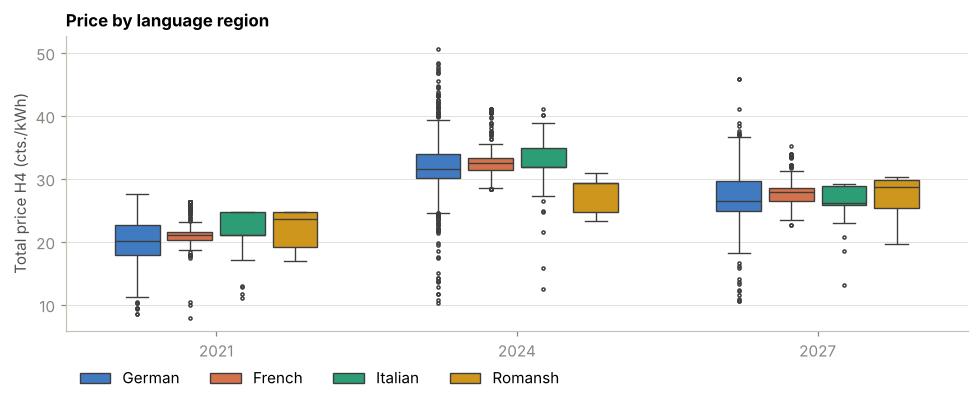

In [20]:
lang_r = df.melt(id_vars="sprachregion", value_vars=[f"total_{j}" for j in JAHRE],
                 var_name="jahr", value_name="preis")
lang_r["jahr"] = lang_r["jahr"].str[-4:]
# English names for display only, directly before plotting
lang_r["sprachregion"] = lang_r["sprachregion"].map(ANZEIGE_SPRACHE)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=lang_r, x="jahr", y="preis", hue="sprachregion",
            hue_order=[ANZEIGE_SPRACHE[r] for r in REGIONEN],
            palette={ANZEIGE_SPRACHE[r]: f for r, f in REGION_FARBE.items()},
            width=0.7, fliersize=2, linewidth=0.9, gap=0.15, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Total price H4 (cts./kWh)")
ax.set_title("Price by language region", loc="left")
ax.legend(title="", frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.08))
fig.tight_layout()

The Romansh group comprises only 16 municipalities. Its means fluctuate accordingly and should not be over-interpreted.

### 6.2 Cantons

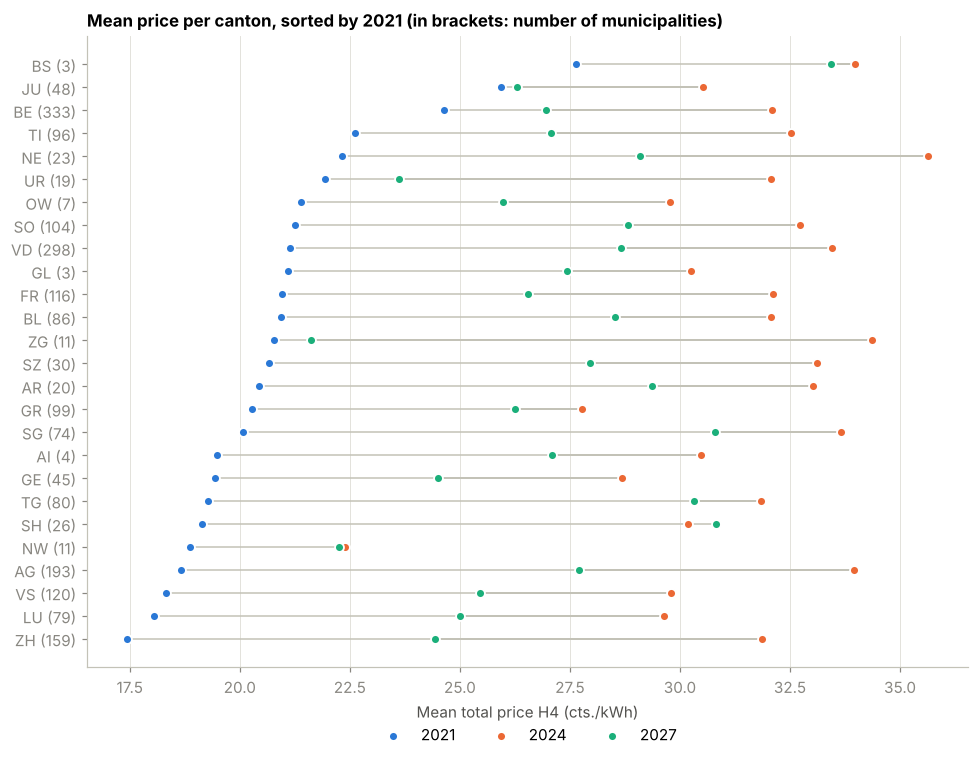

In [21]:
kanton_mittel = df.groupby("kanton")[[f"total_{j}" for j in JAHRE]].mean()
kanton_mittel["n"] = df["kanton"].value_counts()
kanton_mittel = kanton_mittel.sort_values("total_2021")

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(kanton_mittel))
for j in JAHRE:
    ax.scatter(kanton_mittel[f"total_{j}"], y, color=FARBE[j], s=34, label=str(j), zorder=3,
               edgecolors="white", linewidths=1.2)
for i, (_, zeile) in enumerate(kanton_mittel.iterrows()):
    ax.plot([zeile[f"total_{j}"] for j in JAHRE], [i] * 3, color="#c3c2b7", linewidth=1, zorder=2)
ax.set_yticks(y, [f"{k} ({int(n)})" for k, n in zip(kanton_mittel.index, kanton_mittel["n"])])
ax.set_xlabel("Mean total price H4 (cts./kWh)")
ax.set_title("Mean price per canton, sorted by 2021 (in brackets: number of municipalities)", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.07))
ax.grid(axis="y", visible=False)
fig.tight_layout()

#### Interpretation

The differences between the language regions are small. In 2021, German-speaking Switzerland was on average about 1 ct. cheaper than French-speaking Switzerland and 1.5 cts. cheaper than Ticino. In 2027 the three large regions are almost level (27.2, 27.5 and 26.8 cts.). The dispersion stands out: French-speaking Switzerland has a very narrow box, German-speaking Switzerland a wide one. This is related to how many operators a region has (section 8.1: 425 operators in German-speaking Switzerland, 32 in French-speaking Switzerland).

Between the cantons the differences are much larger, and the order shifts. Zurich was the cheapest canton in 2021 at 17.4 cts.; in 2027 it ranks 4th of 26 at 24.4 cts. (only Zug, Nidwalden and Uri are cheaper). Aargau rose from 18.7 to 34.0 cts. (2024), Neuchâtel to 35.6 cts. Nidwalden and Graubünden remained comparatively cheap in 2024 as well.

Small cantons with few municipalities (Basel-Stadt 3, Glarus 3, Appenzell Innerrhoden 4) are means over very few values and therefore say little.

## 7 · Grid operators

Prices are set not by the municipalities but by the grid operators. All municipalities of one operator have the same price (except municipalities with several operators). This section measures how strongly this shapes the data.

In [22]:
pro_betreiber = df.groupby("netzbetreiber_id").size()
print(f"Grid operators: {len(pro_betreiber)}")
print(f"Operators with exactly one municipality: {(pro_betreiber == 1).sum()} ({(pro_betreiber == 1).mean():.0%})")
print(f"Largest operator: {pro_betreiber.max()} municipalities "
      f"({df.loc[df['netzbetreiber_id'] == pro_betreiber.idxmax(), 'netzbetreiber'].iloc[0]})")
print(f"The five largest operators together supply {pro_betreiber.nlargest(5).sum()} municipalities "
      f"({pro_betreiber.nlargest(5).sum() / len(df):.0%})")

Grid operators: 485
Operators with exactly one municipality: 387 (80%)
Largest operator: 315 municipalities (BKW Energie AG)
The five largest operators together supply 911 municipalities (44%)


In [23]:
def varianz_zwischen(werte: pd.Series, gruppe: pd.Series) -> float:
    # Share of the variance due to differences between the groups (eta²)
    gesamt = ((werte - werte.mean()) ** 2).sum()
    zwischen = werte.groupby(gruppe).transform("mean")
    return ((zwischen - werte.mean()) ** 2).sum() / gesamt

pd.DataFrame({
    j: {"between grid operators": varianz_zwischen(df[f"total_{j}"], df["netzbetreiber_id"]),
        "between cantons": varianz_zwischen(df[f"total_{j}"], df["kanton"]),
        "between language regions": varianz_zwischen(df[f"total_{j}"], df["sprachregion"])}
    for j in JAHRE
}).map(lambda v: f"{v:.1%}")

,2021,2024,2027
between grid operators,95.0%,94.0%,96.8%
between cantons,60.3%,23.1%,35.2%
between language regions,3.0%,1.7%,0.4%


#### Interpretation

The supply structure is extremely unequal. 80 percent of the 485 operators supply exactly one municipality, while the five largest together supply 44 percent of all municipalities, BKW alone 315.

The grid operator explains 94 to 97 percent of the price differences between municipalities. Whoever knows which operator supplies a municipality knows its price almost completely. The canton explains 60 percent (2021), 23 percent (2024) and 35 percent (2027), the language region only 0.4 to 3 percent.

Two consequences for the further analysis:

1. Municipal characteristics can only affect the price through the operator. A relationship between density and price therefore really means: dense municipalities are supplied by different operators than rural ones.
2. The 2,087 municipalities are not independent observations. Tests at municipality level give p-values that are too small. Every test in section 8 is therefore also computed at operator level.

## 8 · Statistical tests

Significance level 5 percent. Because many tests are computed, the Bonferroni correction is also given for the correlations.

**Caveat for all tests at municipality level:** the municipalities are not independent observations, because the municipalities of one grid operator have the same price (section 7). The effective sample size is about 500, not 2,087. The p-values therefore come out too small. This is why every test is repeated at operator level.

### 8.1 Prepare the operator level
For each grid operator, the mean price of its municipalities is taken. Canton and language region are those in which most of its municipalities lie.

In [24]:
def haeufigster(x):
    return x.mode().iloc[0]

betreiber = df.groupby("netzbetreiber_id").agg(
    gemeinden=("gemeinde_nr", "size"),
    **{f"total_{j}": (f"total_{j}", "mean") for j in JAHRE},
    anstieg_21_24=("anstieg_21_24", "mean"),
    anstieg_21_27=("anstieg_21_27", "mean"),
    kanton=("kanton", haeufigster),
    sprachregion=("sprachregion", haeufigster),
    einwohner=("einwohner", "sum"),
    flaeche_total=("flaeche_total", "sum"),
    anteil_65plus=("anteil_65plus", "mean"),
)
betreiber["dichte"] = betreiber["einwohner"] / betreiber["flaeche_total"]
mehrere_kantone = df.groupby("netzbetreiber_id")["kanton"].nunique().gt(1).sum()
print(f"{len(betreiber)} grid operators, {mehrere_kantone} of them active in more than one canton")
betreiber["sprachregion"].value_counts().rename(index=ANZEIGE_SPRACHE)

485 grid operators, 18 of them active in more than one canton


sprachregion
German     425
French      32
Italian     21
Romansh      7
Name: count, dtype: int64

### 8.2 Paired t-test: is the price in 2027 higher than in 2021?

The same municipality is measured in two years, hence a paired test. As a cross-check without the normality assumption, the Wilcoxon signed-rank test.

Null hypothesis: the mean price is the same in both years.

In [25]:
zeilen = []
for a, b in paare:
    for ebene, daten in [("Municipalities", df), ("Grid operators", betreiber)]:
        diff = daten[f"total_{b}"] - daten[f"total_{a}"]
        t = stats.ttest_rel(daten[f"total_{b}"], daten[f"total_{a}"])
        w = stats.wilcoxon(daten[f"total_{b}"], daten[f"total_{a}"])
        zeilen.append({"Comparison": f"{a} → {b}", "Level": ebene, "n": len(daten),
                       "mean difference (cts.)": round(diff.mean(), 2),
                       "t": round(t.statistic, 1), "p (t-test)": t.pvalue, "p (Wilcoxon)": w.pvalue})
pd.DataFrame(zeilen)

,Comparison,Level,n,mean difference (cts.),t,p (t-test),p (Wilcoxon)
0,2021 → 2024,Municipalities,2087,11.13,115.7,0.000000e+00,0.000000e+00
1,2021 → 2024,Grid operators,485,12.95,56.4,9.256121e-215,3.560164e-81
2,2024 → 2027,Municipalities,2087,-4.74,-69.7,0.000000e+00,0.000000e+00
3,2024 → 2027,Grid operators,485,-4.09,-19.3,5.664188e-62,4.851966e-51
4,2021 → 2027,Municipalities,2087,6.39,75.7,0.000000e+00,0.000000e+00
5,2021 → 2027,Grid operators,485,8.86,49.0,1.151380e-189,3.582291e-81


#### Interpretation

All three changes are highly significant at both levels; the Wilcoxon test confirms this without the normality assumption. With differences of 4 to 13 centimes and this sample size, that is no surprise.

The difference between the levels is more revealing: computed per operator, the price rose from 2021 to 2027 by 8.9 cts., per municipality by only 6.4 cts. Because each operator counts equally at operator level, this means: the many small operators rose more than the few large ones that supply many municipalities.

The t-test does not count towards bonus point 4, which names only chi-squared, ANOVA and correlation. It does, however, answer the basic question of whether the price increase exists at all.

### 8.3 ANOVA: do prices differ between the language regions?

Null hypothesis: the mean price is the same in all language regions.

The classical ANOVA assumes equal variances in the groups. This is checked with Levene's test. If the assumption is violated, the Alexander-Govern test applies, an ANOVA without the assumption of equal variances. The Kruskal-Wallis test compares ranks instead of means and serves as a cross-check without the normality assumption. Eta² is given as the effect size: the share of price dispersion explained by group membership.

In [26]:
def anova_tabelle(daten: pd.DataFrame, gruppe: str, ziele: list, ebene: str) -> pd.DataFrame:
    zeilen = []
    for ziel in ziele:
        gruppen = [g[ziel].values for _, g in daten.groupby(gruppe) if len(g) >= 2]
        # Alexander-Govern weights by 1/variance and needs groups with dispersion.
        # Cantons in which all municipalities have the same price drop out there.
        mit_streuung = [g for g in gruppen if np.ptp(g) > 0]
        f = stats.f_oneway(*gruppen)
        zeilen.append({
            "Level": ebene, "Variable": ZIELE.get(ziel, ziel), "Groups": len(gruppen), "n": sum(map(len, gruppen)),
            "F": round(f.statistic, 1), "p (ANOVA)": f.pvalue,
            "p (Levene)": stats.levene(*gruppen).pvalue,
            "p (Alexander-Govern)": stats.alexandergovern(*mit_streuung).pvalue,
            "Groups without dispersion": len(gruppen) - len(mit_streuung),
            "p (Kruskal-Wallis)": stats.kruskal(*gruppen).pvalue,
            "eta²": round(varianz_zwischen(daten[ziel], daten[gruppe]), 3),
        })
    return pd.DataFrame(zeilen)

ZIEL_SPALTEN = ["total_2021", "total_2024", "total_2027", "anstieg_21_24", "anstieg_21_27"]
anova_region = pd.concat([
    anova_tabelle(df, "sprachregion", ZIEL_SPALTEN, "Municipalities"),
    anova_tabelle(betreiber, "sprachregion", ZIEL_SPALTEN, "Grid operators"),
], ignore_index=True)
anova_region

,Level,Variable,Groups,n,F,p (ANOVA),p (Levene),p (Alexander-Govern),Groups without dispersion,p (Kruskal-Wallis),eta²
0,Municipalities,Price 2021,4,2087,21.4,1.184506e-13,7.634853e-29,1.362372e-15,0,3.778367e-24,0.030
1,Municipalities,Price 2024,4,2087,11.8,1.232976e-07,1.178384e-19,1.947145e-08,0,1.125931e-13,0.017
2,Municipalities,Price 2027,4,2087,2.9,3.284969e-02,6.441775e-38,8.909422e-04,0,5.035400e-05,0.004
3,Municipalities,Increase 21–24,4,2087,10.0,1.543401e-06,2.425241e-42,2.423445e-10,0,2.141412e-11,0.014
4,Municipalities,Increase 21–27,4,2087,11.2,2.604794e-07,1.365603e-38,1.486072e-18,0,2.328651e-17,0.016
5,Grid operators,Price 2021,4,485,7.9,3.691010e-05,4.386356e-01,2.303611e-03,0,3.464869e-06,0.047
6,Grid operators,Price 2024,4,485,5.8,6.830808e-04,1.148928e-01,1.986768e-04,0,5.736086e-04,0.035
7,Grid operators,Price 2027,4,485,5.8,7.094119e-04,1.685701e-01,3.624483e-04,0,3.811793e-04,0.035
8,Grid operators,Increase 21–24,4,485,7.4,7.702149e-05,1.046466e-01,1.441284e-05,0,1.039265e-04,0.044
9,Grid operators,Increase 21–27,4,485,9.4,4.757722e-06,3.578022e-02,2.868223e-07,0,5.861611e-07,0.055


The ANOVA only says that at least two groups differ. Which ones is shown by Tukey's post-hoc test (pairwise comparisons with corrected p-values). Shown for 2021, the year with the clearest difference.

In [27]:
gruppen_2021 = [df.loc[df["sprachregion"] == r, "total_2021"].values for r in REGIONEN]
tukey = stats.tukey_hsd(*gruppen_2021)
tukey_tabelle = pd.DataFrame(
    [{"Group A": ANZEIGE_SPRACHE[REGIONEN[i]], "Group B": ANZEIGE_SPRACHE[REGIONEN[k]],
      "Difference A − B (cts.)": round(gruppen_2021[i].mean() - gruppen_2021[k].mean(), 2),
      "p (Tukey)": round(tukey.pvalue[i, k], 4)}
     for i in range(4) for k in range(i + 1, 4)]
)
tukey_tabelle

,Group A,Group B,Difference A − B (cts.),p (Tukey)
0,German,French,-0.96,0.0000
1,German,Italian,-1.52,0.0000
2,German,Romansh,-1.45,0.2053
3,French,Italian,-0.56,0.2570
4,French,Romansh,-0.49,0.9129
5,Italian,Romansh,0.07,0.9998


### 8.4 ANOVA: do prices differ between the cantons?

In [28]:
anova_kanton = pd.concat([
    anova_tabelle(df, "kanton", ZIEL_SPALTEN, "Municipalities"),
    anova_tabelle(betreiber, "kanton", ZIEL_SPALTEN, "Grid operators"),
], ignore_index=True)
anova_kanton

,Level,Variable,Groups,n,F,p (ANOVA),p (Levene),p (Alexander-Govern),Groups without dispersion,p (Kruskal-Wallis),eta²
0,Municipalities,Price 2021,26,2087,125.3,0.000000e+00,3.498305e-83,0.000000e+00,2,2.121713e-266,0.603
1,Municipalities,Price 2024,26,2087,24.8,4.377534e-99,1.961052e-79,8.089292e-261,2,2.489474e-127,0.231
2,Municipalities,Price 2027,26,2087,44.9,8.187317e-174,2.426995e-81,0.000000e+00,2,9.125054e-181,0.352
3,Municipalities,Increase 21–24,26,2087,51.0,1.607812e-194,3.941107e-86,1.973079e-266,2,8.415157e-172,0.382
4,Municipalities,Increase 21–27,26,2087,76.0,2.727213e-270,4.660297e-76,0.000000e+00,2,4.157398e-195,0.480
5,Grid operators,Price 2021,22,481,10.8,1.083221e-28,2.437072e-08,1.772005e-31,0,1.052206e-26,0.343
6,Grid operators,Price 2024,22,481,7.7,9.173746e-20,4.215374e-04,1.246155e-13,0,8.056244e-16,0.261
7,Grid operators,Price 2027,22,481,10.7,1.174591e-28,2.009798e-03,3.922278e-30,0,4.196303e-27,0.333
8,Grid operators,Increase 21–24,22,481,6.1,4.645004e-15,4.093088e-06,1.814931e-12,0,1.638722e-12,0.224
9,Grid operators,Increase 21–27,22,481,6.3,1.500779e-15,5.751382e-03,8.407687e-22,0,1.762228e-16,0.228


#### Interpretation: language region

The ANOVA is significant in all years, at municipality and at operator level. At municipality level Levene's test shows unequal variances, so the Alexander-Govern test is decisive, and it confirms the result. The effect, however, is small: the language region explains 3.0 percent of the price differences in 2021 and only 0.4 percent in 2027. Significant does not mean important here.

Tukey's test shows where the differences lie: in 2021 German-speaking Switzerland was significantly cheaper than French-speaking Switzerland (−0.96 cts.) and Ticino (−1.52 cts.). The Romansh municipalities do not differ significantly from any region, which is hardly possible with 16 municipalities.

#### Interpretation: canton

The canton is highly significant at both levels, and the effect is large. At municipality level it explains 60 percent (2021), 23 percent (2024) and 35 percent (2027) of the differences. At operator level the decline in 2024 is weaker: 34, 26 and 33 percent. Part of the strong canton effect in 2021 at municipality level therefore stems from individual large cantonal operators that supplied many municipalities at the same low price.

In Basel-Stadt and Obwalden all municipalities have the same price. These two cantons drop out of the Alexander-Govern test, because it needs groups with dispersion; this does not change the result. At operator level there are 22 instead of 26 cantons, because cantons with only one operator have no dispersion within the group for an ANOVA.

For the research question this means: the differences between the cantons are still large in 2027, while those between the language regions have practically disappeared.

### 8.5 Correlation with p-values: which characteristics are related to the price?

Pearson on the log-transformed characteristics (linear relationship) and Spearman on the raw values (monotonic relationship). Null hypothesis: the correlation is zero.

5 characteristics times 5 target variables are computed, i.e. 25 tests per method. The Bonferroni threshold is therefore 0.05 / 25 = 0.002.

In [29]:
BONFERRONI = 0.05 / (len(MERKMALE) * len(ZIELE))

def korrelationen(daten: pd.DataFrame, ebene: str) -> pd.DataFrame:
    zeilen = []
    for m in MERKMALE:
        if m not in daten:
            continue
        for ziel, name in ZIELE.items():
            paar = daten[[m, ziel]].dropna()
            x_lin = paar[m] if m == "anteil_65plus" else np.log10(paar[m])
            p = stats.pearsonr(x_lin, paar[ziel])
            s = stats.spearmanr(paar[m], paar[ziel])
            zeilen.append({"Level": ebene, "Characteristic": MERKMAL_NAME[m], "Variable": name, "n": len(paar),
                           "Pearson r": round(p.statistic, 3), "p (Pearson)": p.pvalue,
                           "Spearman rho": round(s.statistic, 3), "p (Spearman)": s.pvalue,
                           "significant after Bonferroni": p.pvalue < BONFERRONI and s.pvalue < BONFERRONI})
    return pd.DataFrame(zeilen)

korr_gemeinden = korrelationen(df, "Municipalities")
pd.options.display.float_format = lambda v: f"{v:.3g}"
korr_gemeinden

,Level,Characteristic,Variable,n,Pearson r,p (Pearson),Spearman rho,p (Spearman),significant after Bonferroni
0,Municipalities,Population,Price 2021,2087,-0.145,3.05e-11,-0.169,8.03e-15,True
1,Municipalities,Population,Price 2024,2087,0.115,1.45e-07,0.085,9.75e-05,True
2,Municipalities,Population,Price 2027,2087,0.031,0.159,-0.023,0.297,False
3,Municipalities,Population,Increase 21–24,2087,0.196,1.89e-19,0.195,2.56e-19,True
4,Municipalities,Population,Increase 21–27,2087,0.137,3.7e-10,0.112,2.91e-07,True
5,Municipalities,Density (pop./km²),Price 2021,2087,-0.134,8.75e-10,-0.206,1.62e-21,True
6,Municipalities,Density (pop./km²),Price 2024,2087,0.205,3.72e-21,0.142,6.49e-11,True
7,Municipalities,Density (pop./km²),Price 2027,2087,0.07,0.00141,-0.013,0.556,False
8,Municipalities,Density (pop./km²),Increase 21–24,2087,0.264,1.29e-34,0.271,2.39e-36,True
9,Municipalities,Density (pop./km²),Increase 21–27,2087,0.159,2.91e-13,0.164,4.18e-14,True


In [30]:
# Cross-check at operator level (jobs are missing there because they are suppressed for 88 municipalities)
korr_betreiber = korrelationen(betreiber, "Grid operators")
vergleich = korr_gemeinden.merge(korr_betreiber, on=["Characteristic", "Variable"], suffixes=(" mun.", " op."))
vergleich[["Characteristic", "Variable", "Spearman rho mun.", "p (Spearman) mun.",
           "Spearman rho op.", "p (Spearman) op.", "significant after Bonferroni op."]]

,Characteristic,Variable,Spearman rho mun.,p (Spearman) mun.,Spearman rho op.,p (Spearman) op.,significant after Bonferroni op.
0,Population,Price 2021,-0.169,8.03e-15,0.234,1.83e-07,True
1,Population,Price 2024,0.085,9.75e-05,0.167,0.000227,True
2,Population,Price 2027,-0.023,0.297,-0.056,0.221,False
3,Population,Increase 21–24,0.195,2.56e-19,0.068,0.136,False
4,Population,Increase 21–27,0.112,2.91e-07,-0.195,1.47e-05,True
5,Density (pop./km²),Price 2021,-0.206,1.62e-21,0.047,0.3,False
6,Density (pop./km²),Price 2024,0.142,6.49e-11,0.272,1.11e-09,True
7,Density (pop./km²),Price 2027,-0.013,0.556,0.024,0.602,False
8,Density (pop./km²),Increase 21–24,0.271,2.39e-36,0.268,1.9e-09,True
9,Density (pop./km²),Increase 21–27,0.164,4.18e-14,0.019,0.676,False


#### Interpretation

At municipality level, most relationships in 2021 and 2024 are significant even after Bonferroni, and not a single one in 2027. This confirms the finding from section 5: the relationships existed before the crisis and at its peak, with opposite signs, and have disappeared by 2027.

The cross-check at operator level separates robust from uncertain findings.

Robust, significant after Bonferroni at both levels and with the same sign:

- Share aged 65+ and increase (21–24 and 21–27): negative. Older municipalities had a smaller increase.
- Density and price 2024, and density and increase 21–24: positive. Dense municipalities were more expensive at the peak.
- Area and increase 21–24: negative. Municipalities with a large area rose less.

Not robust:

- Density and price 2021 (municipalities −0.21, operators 0.05 and not significant). The low price of dense municipalities in 2021 goes back to a few large urban operators and does not hold for operators in general.
- Population and increase 21–27 reverse their sign (+0.11 and −0.20). At operator level, «population» is the sum of the population supplied, i.e. the size of the operator. Large operators rose less, large municipalities more. These are two different statements.

No relationship with a municipal characteristic reaches an absolute value of 0.28. The characteristics contribute to the explanation, but little.

### 8.6 Correlation with the size of the grid operator

Besides the municipal characteristics, sub-question 2 explicitly names the size of the grid operator. It is measured as the number of municipalities the operator supplies in category H4 in 2027 (`anz_gemeinden_betreiber`, integration documentation, section 7b). It is not a property of the municipality but of its operator, and is therefore reported separately.

At municipality level, each municipality receives the size of its operator. At operator level, each operator counts once. Pearson on the logarithm of the size, Spearman on the raw values. Five tests per method; the Bonferroni threshold is 0.05 / 5 = 0.01.

In [31]:
BONF_GROESSE = 0.05 / len(ZIELE)
betreiber["groesse"] = df.groupby("netzbetreiber_id")["anz_gemeinden_betreiber"].first()

zeilen = []
for ebene, daten, spalte in [("Municipalities", df, "anz_gemeinden_betreiber"), ("Grid operators", betreiber, "groesse")]:
    for ziel, name in ZIELE.items():
        p = stats.pearsonr(np.log10(daten[spalte]), daten[ziel])
        s = stats.spearmanr(daten[spalte], daten[ziel])
        zeilen.append({"Level": ebene, "Variable": name, "n": len(daten),
                       "Pearson r (log)": round(p.statistic, 3), "p (Pearson)": p.pvalue,
                       "Spearman rho": round(s.statistic, 3), "p (Spearman)": s.pvalue,
                       "significant after Bonferroni": p.pvalue < BONF_GROESSE and s.pvalue < BONF_GROESSE})
print(f"Operators with exactly one municipality: {(betreiber['groesse'] == 1).mean():.0%}")
pd.DataFrame(zeilen)

Operators with exactly one municipality: 77%


,Level,Variable,n,Pearson r (log),p (Pearson),Spearman rho,p (Spearman),significant after Bonferroni
0,Municipalities,Price 2021,2087,0.391,3.02e-77,0.442,8.94e-101,True
1,Municipalities,Price 2024,2087,-0.067,0.00228,-0.119,4.57e-08,True
2,Municipalities,Price 2027,2087,-0.195,2.03e-19,-0.205,2.46e-21,True
3,Municipalities,Increase 21–24,2087,-0.323,8.18e-52,-0.329,5.89e-54,True
4,Municipalities,Increase 21–27,2087,-0.458,1.4e-108,-0.444,1.06e-101,True
5,Grid operators,Price 2021,485,0.16,0.000421,0.18,6.69e-05,True
6,Grid operators,Price 2024,485,0.008,0.866,0.042,0.36,False
7,Grid operators,Price 2027,485,-0.09,0.0472,-0.108,0.017,False
8,Grid operators,Increase 21–24,485,-0.079,0.0814,-0.026,0.575,False
9,Grid operators,Increase 21–27,485,-0.211,2.78e-06,-0.213,2.22e-06,True


#### Interpretation

At municipality level, the size of the grid operator is the strongest relationship in the whole notebook. Municipalities of large operators were more expensive in 2021 (rho = 0.44) and afterwards had the smaller increase (rho = −0.33 up to 2024 and −0.44 up to 2027). In 2027 they are slightly cheaper (−0.21). With the 2024 price there is only a weak relationship (rho = −0.12).

At operator level the relationship is much weaker. Only the 2021 price (rho = 0.18) and the increase from 2021 to 2027 (rho = −0.21) remain significant after Bonferroni. 77 percent of operators supply exactly one municipality, so the characteristic has little dispersion at this level.

The difference between the levels has the same cause as in section 8.2: at municipality level, the few large operators shape the result because they supply many municipalities. Notebook 04 checks whether the relationship holds when the municipal characteristics are taken into account at the same time. At municipality level it does, at operator level it does not (notebook 04, section 5).

## 9 · Interim conclusion

### Sub-question 1: differences between municipalities, cantons and language regions

The canton explains a large part of the price differences (23 to 60 percent), the language region almost nothing any more (0.4 percent in 2027). Which component drives the differences reversed with the crisis: grid usage in 2021, energy in 2024, both about equally in 2027.

### Sub-question 2: municipal characteristics

The relationships are weak (at most 0.28) and hold only partly at operator level. Robust are the share aged 65+ and density for the increase from 2021 to 2024. The size of the grid operator is more strongly related to the price (up to 0.44 at municipality level), but it too mainly because of the few large operators (section 8.6).

### Main question: did the relationships change?

Yes. The crisis reshuffled the ranking of the municipalities almost completely (rho = 0.08 between 2021 and 2024), several relationships reverse their sign, and in 2027 no relationship is significant any more.

### Caveats

The grid operator explains 94 to 97 percent of the differences. The price of a municipality depends far more on who supplies it than on its own characteristics.

The municipal characteristics come from the years 2016 to 2019, the prices from 2021 to 2027 (section 5).

### Decisions for the second part (regression and k-means)

- Population, density, area and jobs enter the model log-transformed.
- Do not use population and jobs together (r = 0.94); use population and density together only with caution (r = 0.68).
- Target variables: price 2021, 2024 and 2027 with the same model, plus the increase from 2021 to 2024.
- Compute the model with and without canton, to see how much the municipal characteristics explain beyond the canton.
- Cluster the standard errors by grid operator and also compute the model at operator level.
- Two variants because of the missing job figures: 2,087 municipalities without, 1,999 municipalities with this characteristic.

In [32]:
con.close()
pd.reset_option("display.float_format")